In [5]:
import joblib
import sklearn
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier,GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score,roc_auc_score,recall_score,classification_report,confusion_matrix

In [7]:
df = pd.read_csv("dataset-uci.csv")
df

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,1,49,0,0,0,0,0,0,178,88.8,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,1,31,1,0,0,0,0,0,157,53.4,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,1,58,0,0,0,0,0,0,172,96.6,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,1,37,1,0,0,0,0,0,177,88.4,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                          319 no

In [11]:
df.isnull().sum().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

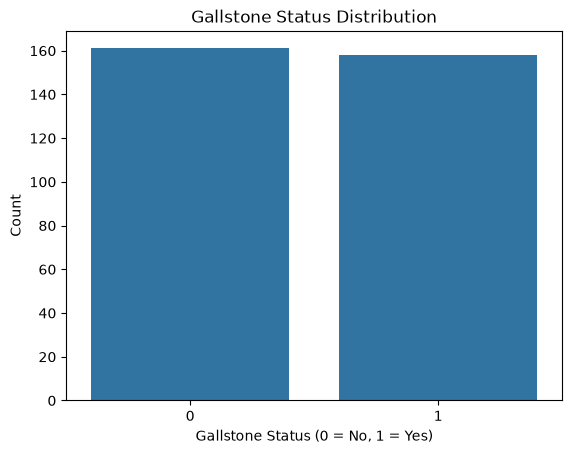

In [15]:
sns.countplot(data=df, x="Gallstone Status")
plt.title("Gallstone Status Distribution")
plt.xlabel("Gallstone Status (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

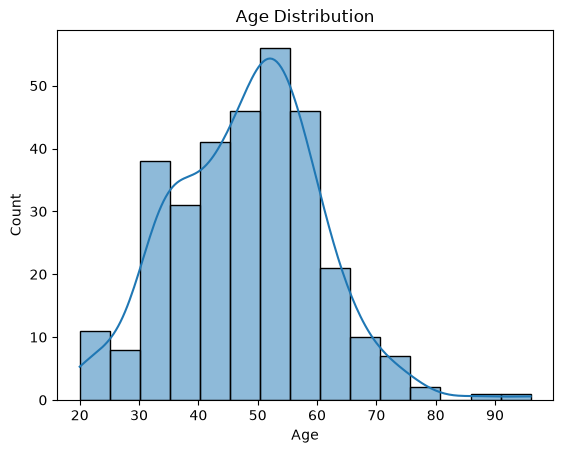

In [17]:
sns.histplot(data=df, x="Age", kde=True)

plt.title("Age Distribution")
plt.show()

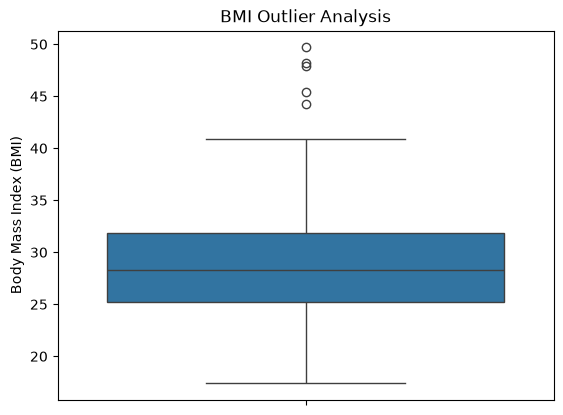

In [18]:
sns.boxplot(data=df, y="Body Mass Index (BMI)")

plt.title("BMI Outlier Analysis")
plt.show()

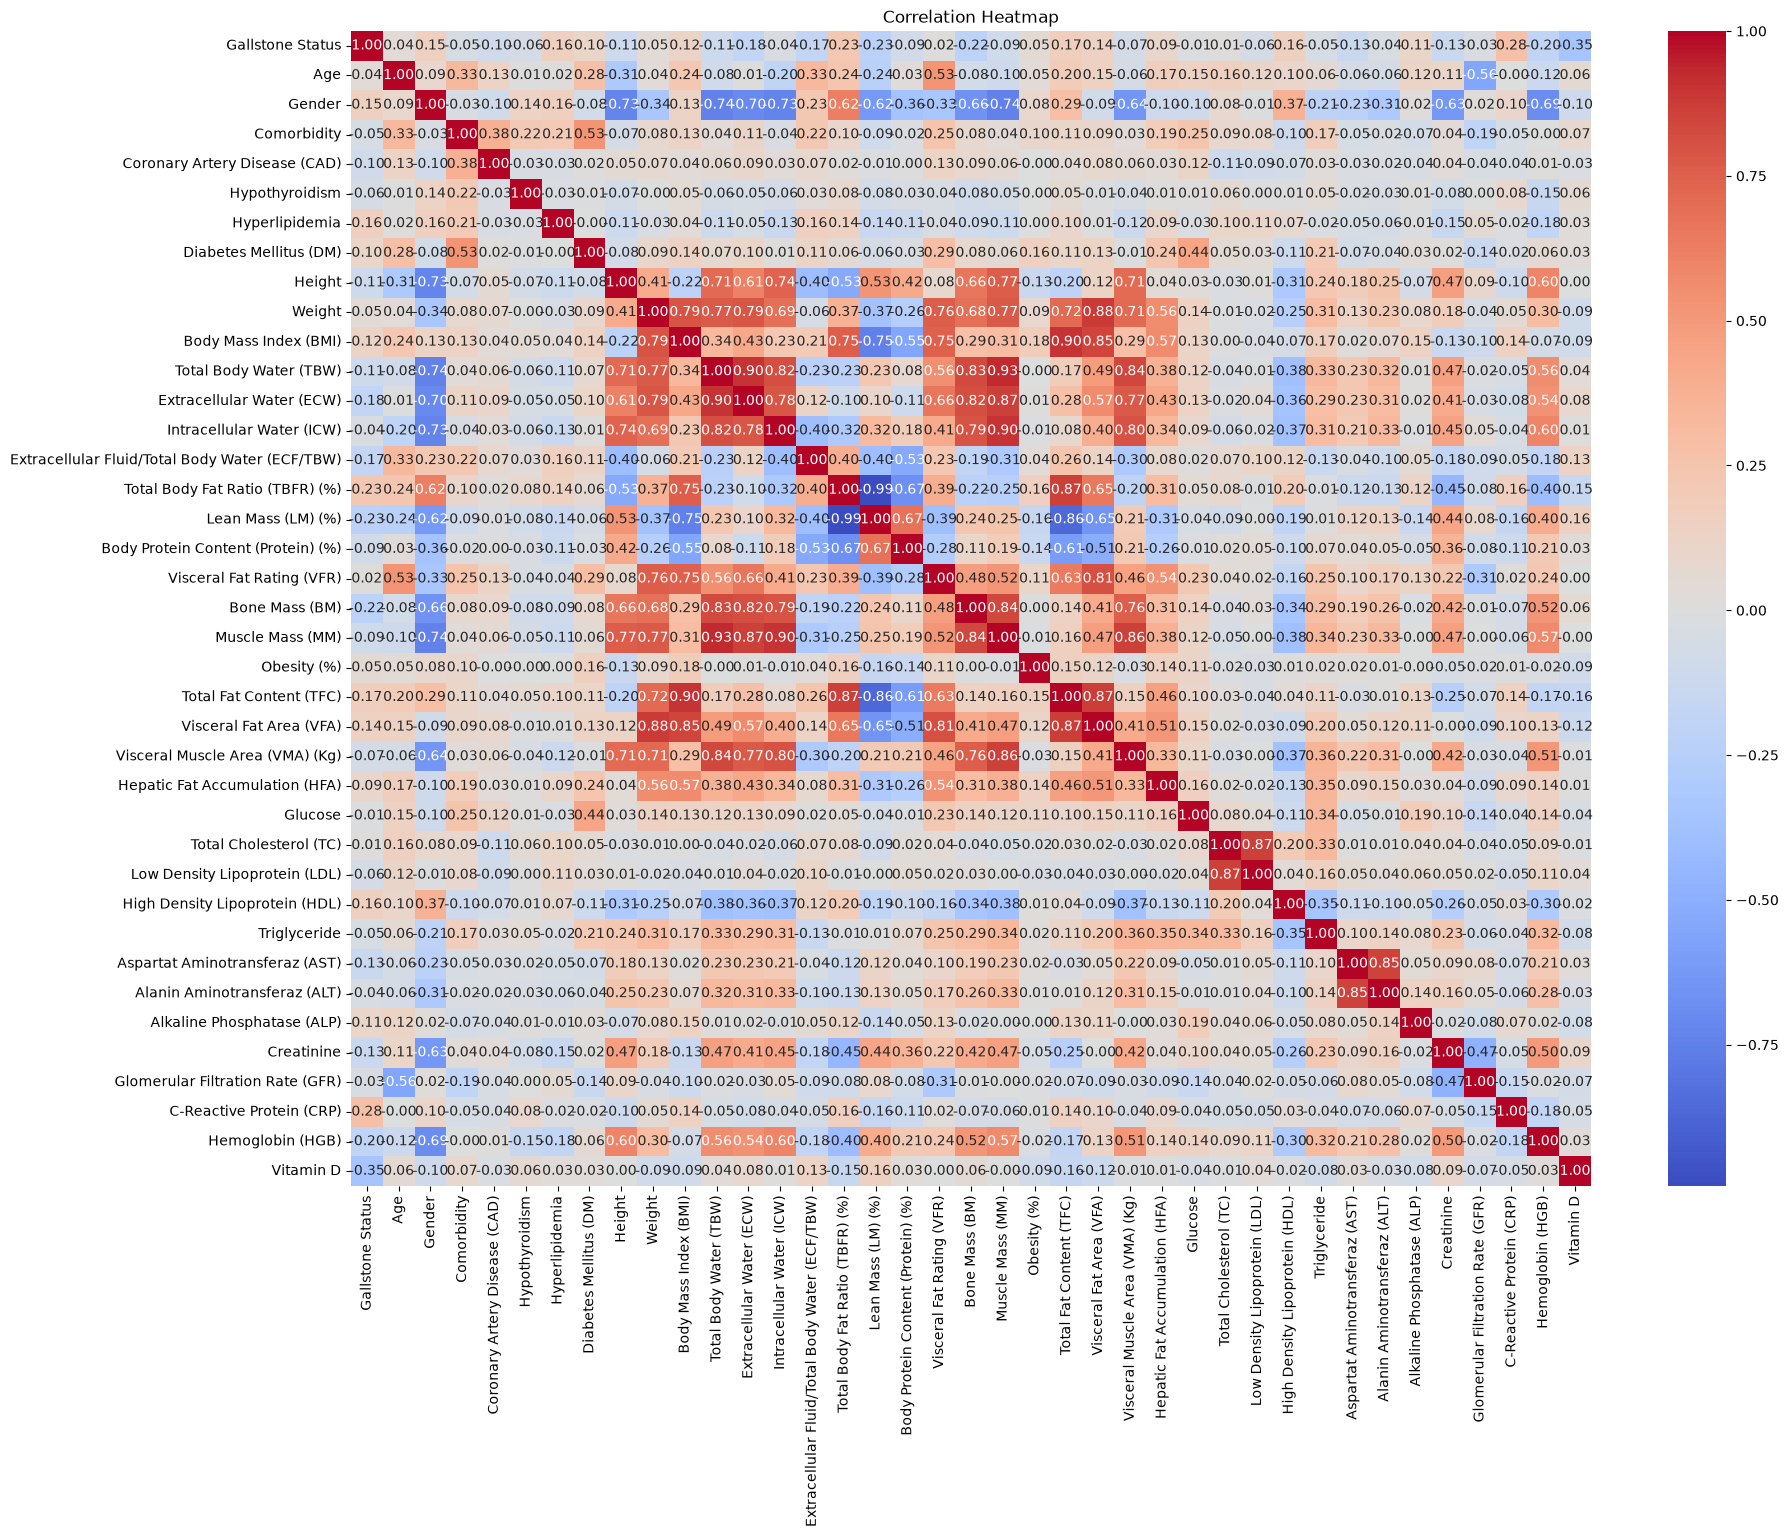

In [21]:
plt.figure(figsize=(20, 15))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [22]:
X= df.drop(columns="Gallstone Status")
y=df["Gallstone Status"]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify =y )

In [24]:
# preprocessing
cont = [c for c in X_train if X_train[c].nunique() > 5]
prep = ColumnTransformer([("scale", StandardScaler(), cont)], remainder="passthrough")
cv = StratifiedKFold(5, shuffle=True, random_state=42)

def make(model):
    return Pipeline([("prep", prep),("select", SelectKBest(score_func=f_classif, k=15)), ("model", model)])

In [25]:

rf = make(RandomForestClassifier(random_state=42))
models = {
    "Logistic Regression": make(LogisticRegression(max_iter=2000)),
    "Decision Tree": make(DecisionTreeClassifier(random_state=42)),
    "Random Forest": rf,
    "Tuned Random Forest": GridSearchCV(rf, {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5, 7,None],
        "model__min_samples_split": [10, 15, 20],
        "model__min_samples_leaf": [5, 8,10],
        "model__max_features": ["sqrt", "log2"],
    }, cv=cv, scoring="f1_macro", n_jobs=-1),
    "Voting Classifier": make(VotingClassifier([
        ("lr", LogisticRegression(max_iter=2000)),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("rf", RandomForestClassifier(random_state=42)),
    ], voting="soft")),
}

In [26]:

rows = []
for name, model in models.items():
    if name =="Tuned Random Forest":
        model.fit(X_train, y_train)
        cv_f1 = model.best_score_
    else:
        cv_f1 = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="f1_macro",n_jobs=-1)
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rows.append({"Model": name,
                 "CV Macro F1": float(cv_f1.mean()),
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "Macro Precision": precision_score(y_test,y_pred,average="macro", zero_division=0),
                 "Macro Recall": recall_score(y_test,y_pred, average="macro", zero_division=0),
                 "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0)
                })

results_df = pd.DataFrame(rows)

results_df = results_df.sort_values(by="Macro F1",ascending=False).reset_index(drop=True)
print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))


Model Comparison:
              Model  CV Macro F1  Accuracy  Macro Precision  Macro Recall  Macro F1
Tuned Random Forest       0.7761    0.8281           0.8284        0.8281    0.8281
Logistic Regression       0.7310    0.8125           0.8125        0.8125    0.8125
      Random Forest       0.7762    0.8125           0.8137        0.8125    0.8123
  Voting Classifier       0.7486    0.6562           0.6569        0.6562    0.6559
      Decision Tree       0.7048    0.6094           0.6095        0.6094    0.6093


In [27]:
best_model = models[results_df.loc[0, "Model"]]
y_pred_best = best_model.predict(X_test)

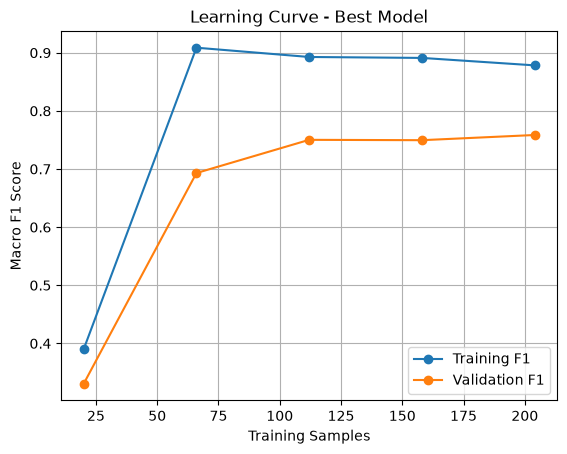

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve

best_model = models["Tuned Random Forest"].best_estimator_

train_sizes, train_scores, val_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_f1 = train_scores.mean(axis=1)
val_f1 = val_scores.mean(axis=1)

plt.plot(train_sizes, train_f1, marker="o", label="Training F1")
plt.plot(train_sizes, val_f1, marker="o", label="Validation F1")

plt.xlabel("Training Samples")
plt.ylabel("Macro F1 Score")
plt.title("Learning Curve - Best Model")
plt.legend()
plt.grid(True)
plt.show() 

In [29]:
print(accuracy_score(y_test,y_pred_best))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_best))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

0.828125

Confusion Matrix:
[[27  5]
 [ 6 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83        32
           1       0.84      0.81      0.83        32

    accuracy                           0.83        64
   macro avg       0.83      0.83      0.83        64
weighted avg       0.83      0.83      0.83        64



In [30]:
from sklearn.metrics import f1_score

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

print("Training Macro F1:", f1_score(y_train, y_train_pred, average="macro"))
print("Testing Macro F1:", f1_score(y_test, y_test_pred, average="macro"))

Training Macro F1: 0.8704607379812503
Testing Macro F1: 0.828083028083028


In [31]:
y_pred = best_model.predict(X_test)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})
# Display 10 random rows
comparison_df.sample(n=10)

,Actual,Predicted
1,0,0
87,0,0
308,1,1
300,1,1
278,1,1
130,0,0
290,1,1
281,1,0
158,0,0
268,1,1


In [32]:
import pandas as pd

# Create one new record not copied from the dataset
new_data = pd.DataFrame([{
    "Age": 42,
    "Gender": 1,
    "Comorbidity": 1,
    "Coronary Artery Disease (CAD)": 0,
    "Hypothyroidism": 0,
    "Hyperlipidemia": 1,
    "Diabetes Mellitus (DM)": 0,
    "Height": 172,
    "Weight": 84.5,
    "Body Mass Index (BMI)": 28.6,
    "Total Body Water (TBW)": 45.2,
    "Extracellular Water (ECW)": 18.2,
    "Intracellular Water (ICW)": 27.0,
    "Extracellular Fluid/Total Body Water (ECF/TBW)": 40.3,
    "Total Body Fat Ratio (TBFR) (%)": 28.5,
    "Lean Mass (LM) (%)": 71.5,
    "Body Protein Content (Protein) (%)": 17.2,
    "Visceral Fat Rating (VFR)": 12,
    "Bone Mass (BM)": 3.1,
    "Muscle Mass (MM)": 58.7,
    "Obesity (%)": 29.4,
    "Total Fat Content (TFC)": 24.8,
    "Visceral Fat Area (VFA)": 14.2,
    "Visceral Muscle Area (VMA) (Kg)": 35.6,
    "Hepatic Fat Accumulation (HFA)": 0,
    "Glucose": 98,
    "Total Cholesterol (TC)": 205,
    "Low Density Lipoprotein (LDL)": 128,
    "High Density Lipoprotein (HDL)": 48,
    "Triglyceride": 145,
    "Aspartat Aminotransferaz (AST)": 22,
    "Alanin Aminotransferaz (ALT)": 25,
    "Alkaline Phosphatase (ALP)": 82,
    "Creatinine": 0.9,
    "Glomerular Filtration Rate (GFR)": 102.5,
    "C-Reactive Protein (CRP)": 1.8,
    "Hemoglobin (HGB)": 14.2,
    "Vitamin D": 29.5
}])

# Match the exact feature order used during training
new_data = new_data[X_train.columns]

# Predict with your selected best model
prediction = best_model.predict(new_data)

print("Predicted Gallstone Status:", prediction[0])

Predicted Gallstone Status: 1


In [33]:
with open("gallstone.pkl", "wb") as f:
    joblib.dump(best_model, f)

print(" Model trained & saved successfully")

 Model trained & saved successfully
